<a href="https://colab.research.google.com/github/sajid-naeem-dev/book-data-scraper/blob/main/book_scraper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!pip install -q requests beautifulsoup4 pandas openpyxl

In [9]:
import requests
from bs4 import BeautifulSoup

URL = "https://books.toscrape.com/catalogue/page-1.html"

response = requests.get(URL, timeout=20)
response.encoding = "utf-8"
print("Status:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")
books = soup.select("article.product_pod")
print("Books found on this page:", len(books))

first = books[0]
print("Title:", first.h3.a["title"])
print("Price:", first.select_one("p.price_color").text)
print("Rating class:", first.select_one("p.star-rating")["class"])
print("Availability:", first.select_one("p.instock.availability").text.strip())

Status: 200
Books found on this page: 20
Title: A Light in the Attic
Price: £51.77
Rating class: ['star-rating', 'Three']
Availability: In stock


In [10]:
import re
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

BASE = "https://books.toscrape.com/catalogue/page-{}.html"
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
HEADERS = {"User-Agent": "Mozilla/5.0 (learning project: book_scraper)"}

rows = []
failed_pages = []

for page in range(1, 51):
    url = BASE.format(page)
    try:
        r = requests.get(url, headers=HEADERS, timeout=20)
        r.raise_for_status()
        r.encoding = "utf-8"
    except requests.RequestException as e:
        failed_pages.append(page)
        print(f"Page {page} failed: {e}")
        continue

    soup = BeautifulSoup(r.text, "html.parser")
    for book in soup.select("article.product_pod"):
        price_text = book.select_one("p.price_color").text
        rating_word = [c for c in book.select_one("p.star-rating")["class"] if c != "star-rating"][0]
        rows.append({
            "title": book.h3.a["title"],
            "price_gbp": float(re.sub(r"[^\d.]", "", price_text)),
            "rating": RATING_MAP.get(rating_word),
            "in_stock": "In stock" in book.select_one("p.availability").text,
            "url": urljoin(url, book.h3.a["href"]),
        })

    if page % 10 == 0:
        print(f"Done page {page}, books so far: {len(rows)}")
    time.sleep(0.5)

df = pd.DataFrame(rows)
print("\nTotal books:", len(df))
print("Failed pages:", failed_pages)
print(df.shape)
df.head()

Done page 10, books so far: 200
Done page 20, books so far: 400
Done page 30, books so far: 600
Done page 40, books so far: 800
Done page 50, books so far: 1000

Total books: 1000
Failed pages: []
(1000, 5)


,title,price_gbp,rating,in_stock,url
0,A Light in the Attic,51.77,3,True,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,True,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,True,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,True,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,True,https://books.toscrape.com/catalogue/sapiens-a...


In [11]:
print(df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate titles:", df.duplicated(subset="title").sum())
print("Duplicate URLs:", df.duplicated(subset="url").sum())
print("\nPrice range:", df["price_gbp"].min(), "to", df["price_gbp"].max())
print("\nBooks per rating:\n", df["rating"].value_counts().sort_index())
print("\nIn stock:", int(df["in_stock"].sum()), "of", len(df))

title         object
price_gbp    float64
rating         int64
in_stock        bool
url           object
dtype: object

Missing values:
 title        0
price_gbp    0
rating       0
in_stock     0
url          0
dtype: int64

Duplicate titles: 1
Duplicate URLs: 0

Price range: 10.0 to 59.99

Books per rating:
 rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

In stock: 1000 of 1000


                 Metric    Value
0           Total books  1000.00
1   Average price (GBP)    35.07
2    Median price (GBP)    35.98
3        Cheapest (GBP)    10.00
4  Most expensive (GBP)    59.99
5        Average rating     2.92
6        Books in stock  1000.00 

   rating  books  avg_price_gbp
0       1    226          34.56
1       2    196          34.81
2       3    203          34.69
3       4    179          36.09
4       5    196          35.37


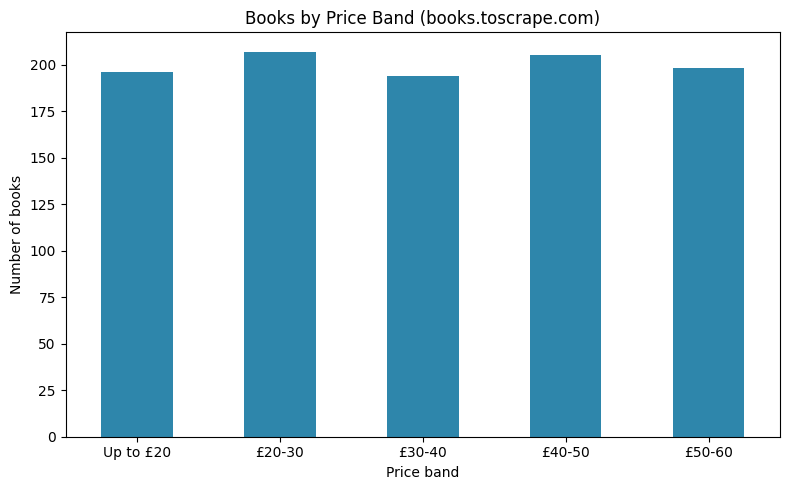

In [12]:
import matplotlib.pyplot as plt
from openpyxl.styles import Font, PatternFill
from openpyxl.utils import get_column_letter

# 1. Clean: remove duplicate pages and add price bands
df = df.drop_duplicates(subset="url").reset_index(drop=True)
bands = ["Up to £20", "£20-30", "£30-40", "£40-50", "£50-60"]
df["price_band"] = pd.cut(df["price_gbp"], bins=[0, 20, 30, 40, 50, 60], labels=bands)

# 2. Summary tables
summary = pd.DataFrame({
    "Metric": ["Total books", "Average price (GBP)", "Median price (GBP)",
               "Cheapest (GBP)", "Most expensive (GBP)", "Average rating", "Books in stock"],
    "Value": [len(df), round(df["price_gbp"].mean(), 2), round(df["price_gbp"].median(), 2),
              df["price_gbp"].min(), df["price_gbp"].max(),
              round(df["rating"].mean(), 2), int(df["in_stock"].sum())],
})
by_rating = (df.groupby("rating")
               .agg(books=("title", "count"), avg_price_gbp=("price_gbp", "mean"))
               .round(2).reset_index())
print(summary, "\n")
print(by_rating)

# 3. Excel report with formatting
with pd.ExcelWriter("books_report.xlsx", engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Books", index=False)
    summary.to_excel(writer, sheet_name="Summary", index=False)
    by_rating.to_excel(writer, sheet_name="By Rating", index=False)
    for ws in writer.book.worksheets:
        ws.freeze_panes = "A2"
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="2E86AB")
        for i, col in enumerate(ws.columns, 1):
            longest = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[get_column_letter(i)].width = min(longest + 3, 60)

# 4. Chart: books per price band
counts = df["price_band"].value_counts().reindex(bands)
plt.figure(figsize=(8, 5))
counts.plot(kind="bar", color="#2E86AB")
plt.title("Books by Price Band (books.toscrape.com)")
plt.xlabel("Price band")
plt.ylabel("Number of books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("price_distribution.png", dpi=150)
plt.show()